# Forecasting Next-Week Volatility of S&P 500 Stocks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qqgjyx/AC-209A_VolForecast/blob/main/ms2.ipynb)

**Milestone 2: data wrangling and project redefinition.**

Canvas project group 38: Ashley Lee, Juntang Wang, Shuo Yang, Simon Manivong, Terry Su.
TF mentor: Daniel More Torres. Project 12 on the approved projects list.

**What this notebook does:**
1. **Gets** point-in-time S&P 500 membership, daily Yahoo prices for every past and present member,
   Alpaca bars for members Yahoo lacks (from 2016) and 5-minute bars for every member since 2016, the
   S&P 500 ETF, five FRED market series and, when an SEC contact is set, the filing times of SEC
   8-K Item 2.02 earnings releases, a proxy for the announcement time.
2. **Understands** the raw stock-day table: what a row is, each column, shape, types, summary statistics.
3. **Cleans** it step by step, with the reason for each step, and builds the modeling table: one row
   per stock-week with the target and every feature known at that week's Friday close.
4. **States** the revised project question so that it can be checked at the end of the project.

EDA and baseline models are Milestone 3. The code lives in `src/volforecast/`; this notebook calls it.

## Setup

On Colab this clones the repo and installs it. Locally it only loads `.env`.

> **No setup needed.** On a first run the cell below downloads our data snapshot (138 MB, from
> Google Drive): every cache this notebook reads except CRSP. No keys are needed, Run all takes a
> few minutes, and the numbers match the committed outputs.
>
> **To fetch from the sources instead**, set `SNAPSHOT_URL=""` in `.env`: the notebook then
> downloads everything itself: about 450 MB in about 10 minutes, and
> two sources need keys in `.env`: Alpaca (`ALPACA_API_KEY_ID`, `ALPACA_API_SECRET_KEY`, from a
> free paper-trading account) and SEC (`SEC_USER_AGENT="Your Name your@email"`, as SEC's
> fair-access policy asks). Without the keys the Alpaca fill, the earnings columns and the
> 5-minute check are skipped, so some counts and takeaways differ from what you see. Section 3l
> needs a personal WRDS account in either case.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:  # reload src/ edits; Colab's IPython autoreload imports `imp`, gone since 3.12
    %load_ext autoreload
    %autoreload 2
if IN_COLAB and not Path("pyproject.toml").exists():
    !test -d AC-209A_VolForecast || git clone -q https://github.com/qqgjyx/AC-209A_VolForecast.git
    %cd AC-209A_VolForecast
    !pip install -q -e .
    sys.path.insert(0, str(Path("src").resolve()))  # the install is importable only after a restart
from dotenv import load_dotenv

load_dotenv(Path(".env"))  # API keys, if a .env exists
print("Running in Colab:", IN_COLAB)

# Our cached data behind the committed outputs, CRSP excluded; "" fetches every source instead
SNAPSHOT_URL = os.environ.get("SNAPSHOT_URL", "https://drive.google.com/file/d/1okSRcNb2W-rL7BoRqtIPz2NjxfukHrYK/view?usp=sharing")
if SNAPSHOT_URL and not Path("data/prices").exists():
    from volforecast.data import fetch_snapshot

    fetch_snapshot(SNAPSHOT_URL, Path("data"))
print("Data:", "cached" if Path("data/prices").exists() else "downloaded on first use")

Running in Colab: False
Data: cached


In [2]:
import pandas as pd

DATA_PATH, OUT_PATH, IMAGES_PATH = Path("data"), Path("out"), Path("images")
START, END = "2005-01-01", "2026-11-07"  # END is exclusive: the last day is Fri 2026-11-06
FRED_SERIES = ["VIXCLS", "VXVCLS", "BAA10Y", "T10Y2Y", "DTB3"]
pd.set_option("display.max_columns", 30, "display.width", 160)

## **Phase 1**: Getting the data

Drives `volforecast.data`: `fetch_membership`, `universe`, `fetch_prices`, `fetch_alpaca_daily`,
`fetch_fred`, `fetch_sec_events`, `fetch_alpaca_rv`, `size_mb`, plus `to_current`, which maps
renamed tickers to the symbol that now carries their history. Each `fetch_*` downloads once and caches under `data/`; a rerun
reads the cache.

In [3]:
# Get 1a: point-in-time S&P 500 membership (github.com/fja05680/sp500, pinned commit)
from volforecast.data import RENAMES, fetch_membership, to_current, universe

raw_membership = fetch_membership(DATA_PATH / "sp500_membership.csv")
membership = to_current(raw_membership)  # BK -> BNY, ANTM -> ELV, ... (see 3a)
TICKERS = universe(membership, START)
per_date = membership.groupby("date").size()
print(f"{per_date.size:,} snapshots from {per_date.index[0]:%Y-%m-%d} to {per_date.index[-1]:%Y-%m-%d}, "
      f"{per_date.min()} to {per_date.max()} members each")
print(f"{len(universe(raw_membership, START))} tickers were in the index at some point since {START}; "
      f"{len(TICKERS)} companies after mapping {len(RENAMES)} renamed tickers")

2,720 snapshots from 1996-01-02 to 2026-08-18, 487 to 507 members each
977 tickers were in the index at some point since 2005-01-01; 950 companies after mapping 30 renamed tickers


In [4]:
# Get 1b: daily Yahoo prices for every company
from volforecast.data import fetch_prices

prices = fetch_prices(TICKERS, START, END, DATA_PATH / "prices").assign(source="yahoo")
missing = sorted(set(TICKERS) - set(prices.index.unique("ticker")))
N_YAHOO = len(TICKERS) - len(missing)
print(f"{len(prices):,} stock-days; Yahoo has {N_YAHOO} of {len(TICKERS)} companies")
print(f"missing, e.g.: {missing[:10]}")

3,208,209 stock-days; Yahoo has 677 of 950 companies
missing, e.g.: ['AABA', 'ABKFQ', 'ABMD', 'ABS', 'ACAS', 'ACS', 'AET', 'AGN', 'AKS', 'ALTR']


In [5]:
# Get 1c: Alpaca daily bars from 2016 for tickers Yahoo lacks (needs ALPACA_* keys or the snapshot)
from volforecast.data import ALPACA_START, fetch_alpaca_daily

HAS_KEYS = all(os.environ.get(k) for k in ["ALPACA_API_KEY_ID", "ALPACA_API_SECRET_KEY"])
HAS_ALPACA = HAS_KEYS or (DATA_PATH / "alpaca_daily").exists()
if HAS_ALPACA:
    alpaca = fetch_alpaca_daily(missing, END, DATA_PATH / "alpaca_daily").assign(source="alpaca")
    prices = pd.concat([prices, alpaca]).sort_index()
    print(f"Alpaca has {alpaca.index.unique('ticker').size} of the {len(missing)} companies Yahoo lacks: "
          f"{len(alpaca):,} stock-days from {ALPACA_START}")
found = set(prices.index.unique("ticker"))
missing = sorted(set(TICKERS) - found)
print(f"{len(missing)} companies have no data from either source")

Alpaca has 165 of the 273 companies Yahoo lacks: 214,802 stock-days from 2016-01-01
108 companies have no data from either source


In [6]:
# Get 1d: market-wide series: the S&P 500 ETF (SPY) and five FRED series
from volforecast.data import fetch_fred

spy = fetch_prices(["SPY"], START, END, DATA_PATH / "market")
fred = fetch_fred(FRED_SERIES, DATA_PATH / "fred").loc[START:]
fred.describe().T[["count", "mean", "min", "max"]]

,count,mean,min,max
VIXCLS,5529.0,19.099405,9.14,82.69
VXVCLS,4761.0,21.583705,11.85,72.98
BAA10Y,5461.0,2.394287,1.36,6.16
T10Y2Y,5467.0,0.953241,-1.08,2.91
DTB3,5466.0,1.789415,-0.05,5.36


In [7]:
# Get 1e: filing times of SEC 8-K Item 2.02 earnings releases (needs SEC_USER_AGENT or the snapshot)
from volforecast.data import fetch_sec_events

last_day = prices.reset_index().groupby("ticker")["date"].max()
LISTED = sorted(last_day.index[last_day >= last_day.max() - pd.Timedelta(days=7)])
if os.environ.get("SEC_USER_AGENT") or (DATA_PATH / "sec" / "company_tickers.json").exists():
    events = fetch_sec_events(LISTED, DATA_PATH / "sec")
    print(f"{len(events):,} earnings filings for {events['ticker'].nunique()} companies, "
          f"{events['accepted'].min():%Y-%m-%d} to {events['accepted'].max():%Y-%m-%d}")
else:
    events = None
    print("no SEC_USER_AGENT and no snapshot: earnings dates skipped (see Setup)")

52,762 earnings filings for 642 companies, 2004-08-25 to 2026-11-09


In [8]:
# Get 1f: 5-minute realized variance from Alpaca: a 24-stock sample, plus every member that
# scripts/build_rv5.py has cached (all 718 since 2016 after its hours-long run)
from volforecast.data import fetch_alpaca_rv, rv_sample

RV_TICKERS = sorted(set(rv_sample(membership)) | {p.stem for p in (DATA_PATH / "rv5").glob("*.parquet")})
rv5 = fetch_alpaca_rv(RV_TICKERS, END, DATA_PATH / "rv5") if HAS_ALPACA else None
print(f"5-minute realized variance: {'skipped (no Alpaca keys or snapshot)' if rv5 is None else f'{len(rv5):,} stock-days'}")

5-minute realized variance: 1,724,119 stock-days


In [9]:
# Get 1g: size of every source on disk
from volforecast.data import size_mb

sizes = pd.Series({p.name: size_mb(p) for p in sorted(DATA_PATH.iterdir())
                   if (p.is_dir() and p.name != "crsp") or p.suffix == ".csv"})  # CRSP: 3l
print(sizes.round(1).to_string())
print(f"total: {sizes.sum():.1f} MB on disk")

alpaca_daily              5.1
fred                      0.9
market                    0.6
prices                   80.9
rv5                      32.4
sec                     347.5
sp500_membership.csv      5.5
total: 472.9 MB on disk


In [10]:
# Get 1h: guard, fails loudly if a download is broken
dates = prices.index.get_level_values("date")
assert prices.index.is_unique, "duplicate (date, ticker) rows"
assert "SPY" not in found, "the canary leaked into the stock data"
assert dates.min() >= pd.Timestamp(START) and dates.max() < pd.Timestamp(END)
assert len(found) >= 0.6 * len(TICKERS), "too few tickers: rate-limited? delete data/prices, rerun"
assert len(spy) > 5000 and fred["VIXCLS"].notna().sum() > 5000
print(f"guard OK: {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}, {dates.nunique():,} trading days")

guard OK: 2005-01-03 to 2026-11-06, 5,497 trading days


**Takeaway.** 977 tickers were in the index at some point since 2005; mapping 30 renamed
tickers to their current symbols leaves 950 companies. Yahoo has 677 of them, Alpaca adds 165 of
the other 273 from 2016 on, and 108 companies, all of which left the index before 2016, have no
free data. Measured month by month in 3a, coverage of index members rises from 55% in 2005 to 96%
in 2016, when Alpaca's history begins, and stays at 99% or more from 2018.

## **Phase 2**: Understanding the data

The price table flattened to plain rows and columns: **one row is one ticker on one trading day.**

| Column | Meaning |
|---|---|
| `date` | trading day |
| `ticker` | symbol as in the membership file (`BRK.B`, not Yahoo's `BRK-B`) |
| `open`, `high`, `low`, `close` | daily prices adjusted for splits only, USD |
| `adj_close` | close adjusted for splits and dividends, USD |
| `volume` | shares traded |
| `source` | `yahoo`, or `alpaca` for members Yahoo lacks |

The membership table has one row per (snapshot date, ticker): the index on that date. FRED and
SPY are one row per day.

In [11]:
# Understand 2a: one row per ticker-day
daily = prices.reset_index()
print(f"{daily.shape[0]:,} rows x {daily.shape[1]} columns")
print(daily["source"].value_counts().to_string())
daily.dtypes

3,423,011 rows x 9 columns
source
yahoo     3208209
alpaca     214802


date         datetime64[us]
ticker                  str
open                float64
high                float64
low                 float64
close               float64
adj_close           float64
volume              float64
source                  str
dtype: object

In [12]:
# Understand 2b: summary statistics of each numerical column
daily.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
open,3423011.0,1.185197e+02,1.527405e+03,0.0001,24.907579,4.823000e+01,9.340000e+01,1.199000e+05
high,3423011.0,1.198509e+02,1.535017e+03,0.0001,25.200001,4.881000e+01,9.446000e+01,1.657000e+05
low,3423011.0,1.171697e+02,1.520921e+03,0.0001,24.559999,4.764679e+01,9.233000e+01,1.095000e+05
close,3423011.0,1.184913e+02,1.526606e+03,0.0001,24.910000,4.823500e+01,9.341000e+01,1.139000e+05
adj_close,3423011.0,8.618169e+01,3.584667e+02,0.0001,18.760000,3.823467e+01,8.189159e+01,3.641127e+04
volume,3423011.0,7.006775e+06,3.685959e+07,0.0000,891500.000000,2.057200e+06,4.877000e+06,3.692928e+09


**Takeaway.** No cell is missing: both sources drop a day rather than leave a gap, so
missing data shows up as missing companies (3a). The extremes are not plausible for S&P 500 stocks,
a high of 165,700 USD (Yahoo's PARA) and prices of 0.0001 USD; Phase 3 removes the series behind
them.

## **Phase 3**: Cleaning and preprocessing

Drives `volforecast.clean` (`clean`, `coverage`), `volforecast.features` (`daily_measures`,
`weekly_panel`, `add_market`, `add_earnings`, `alpha158_weekly`, `build_table`) and
`volforecast.plots`. Every step below says what it removes and why.

### 3a. Renamed tickers and survivorship

Yahoo and Alpaca file a renamed company under its new symbol and drop the old one: BK became BNY
on 2026-05-21, and BNY carries BK's full history. `RENAMES` maps 30 such tickers to their current
symbol, each checked against the new symbol's history. Of the companies Yahoo lacks entirely
(acquired or bankrupt), Alpaca has those still trading in 2016 or later; nothing free covers the
earlier ones, so the sample leans toward survivors before 2016. The plot measures how much,
month by month.

month,2005-12-31,2006-12-31,2007-12-31,2008-12-31,2009-12-31,2010-12-31,2011-12-31,2012-12-31,2013-12-31,2014-12-31,2015-12-31,2016-12-31,2017-12-31,2018-12-31,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31,2026-12-31
"Yahoo, old tickers",0.53,0.56,0.58,0.61,0.63,0.65,0.66,0.68,0.70,0.72,0.73,0.76,0.79,0.81,0.84,0.87,0.89,0.92,0.94,0.96,0.97,0.99
"renames, Alpaca, cleaning",0.55,0.58,0.60,0.63,0.66,0.68,0.69,0.72,0.74,0.76,0.77,0.96,0.98,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00


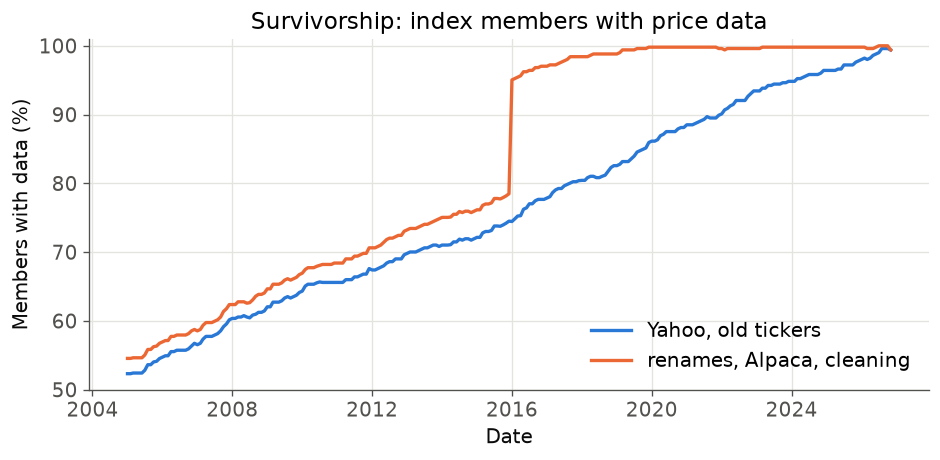

In [13]:
# Clean 3a: share of index members with price data, before and after cleaning
from volforecast.clean import clean, coverage
from volforecast.data import BREAKS, WRONG_SERIES
from volforecast.plots import cleaning_steps
from volforecast.plots import coverage as plot_coverage

clean_daily, steps = clean(daily, membership, set(WRONG_SERIES), {t: d for t, (d, _) in BREAKS.items()}, END)
yahoo_raw = prices.reset_index().query("source == 'yahoo'")
shares = pd.DataFrame({
    "Yahoo, old tickers": coverage(raw_membership, yahoo_raw),
    "renames, Alpaca, cleaning": coverage(membership, clean_daily[clean_daily["in_index"]]),
})
plot_coverage(shares, IMAGES_PATH / "coverage.png")
shares.resample("YE").mean().T.round(2)

### 3b. Cleaning steps

`clean` applies these rules in order and logs the rows each removes. Every rule looks at one row
or at a table built once by hand, never at later rows, so cleaning cannot leak the future.

1. **Index spells.** Keep a ticker's rows only from 120 days before each spell in the index (for
   lagged features) to 14 days after it (for the last target). Yahoo reuses tickers: today's `MI`,
   `CPWR` or `FB` are other securities, and their rows fall outside the old spells.
2. **Wrong series.** Nine tickers whose Yahoo series sits inside a spell but belongs to another
   security (`WRONG_SERIES`, below). They were found as the in-index median dollar volume under
   $5M a day, against $155M for the median member, and each was checked by hand.
3. **Series breaks.** Four series change company or price scale on a date (`BREAKS`, below), found
   as the overnight jumps larger than 2x that are not real events; rows before the date go.
   Yahoo's JCI before the 2016 merger, for instance, is Tyco's history, not Johnson Controls'.
4. **Impossible bars.** A price of zero or less, or an open or close outside the day's range.
5. **No-trade days.** Zero volume: Yahoo carries the last price forward, so the bar is not real.

Then `adjust_prices` applies qlib's Yahoo normalizer: prices times `adj_close / close` and volume
divided by it, so price ratios across days include dividends and spin-offs while price times
volume stays the dollar volume traded. Within a day the factor cancels, so the Garman-Klass target
does not change.

,why the Yahoo series is wrong
CCU,"Clear Channel, private in 2008; Yahoo's CCU is..."
CPWR,"Compuware, private in 2014; Yahoo's CPWR has z..."
EP,"El Paso, acquired in 2012; Yahoo's EP trades ~..."
GENZ,"Genzyme, acquired in 2011; Yahoo's GENZ trades..."
KG,"King Pharmaceuticals, acquired in 2010; Yahoo'..."
PARA,"Paramount, merged in 2025; Yahoo's PARA is pri..."
SII,"Smith International, acquired in 2010; Yahoo's..."
SUN,"Sunoco, acquired in 2012; Yahoo's SUN is Sunoc..."
WEN,"Wendy's International, acquired in 2008; Yahoo..."


,first good date,why
EVHC,2016-12-02,AmSurg took the Envision name; earlier rows ar...
JCI,2016-09-02,Yahoo's JCI before the Tyco merger is Tyco's h...
TGNA,2017-06-01,Alpaca's TGNA before the Cars.com spin-off is ...
WRK,2016-05-16,Alpaca's WRK before this date is on another pr...


,step,removes,rows_left,rows_removed
0,raw rows,,3423011,0
1,index spells,"outside each ticker's index spells, incl. reus...",2327001,1096010
2,wrong series,"another security, same ticker",2319369,7632
3,series breaks,before a change of company or price scale,2315900,3469
4,impossible bars,"price <= 0 or open/close outside [low, high]",2315899,1
5,no-trade days,"zero volume, price carried forward",2315615,284


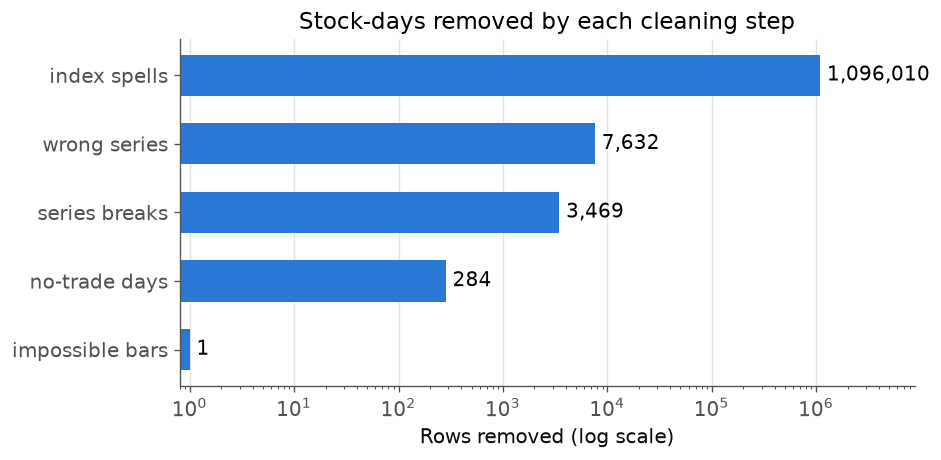

In [14]:
# Clean 3b: rows removed by each step, in order, and the hand-checked wrong series
cleaning_steps(steps, IMAGES_PATH / "cleaning_steps.png")
display(pd.Series(WRONG_SERIES, name="why the Yahoo series is wrong").to_frame())
display(pd.DataFrame(BREAKS, index=["first good date", "why"]).T)
steps

### 3c. Missing data

The cleaned table has no missing cells; what is missing is whole companies (3a). The table below
shows when the companies with no data from either source left the index.

In [15]:
# Clean 3c: missing cells per column, and missing companies by the year they left the index
print("missing cells per column:", clean_daily.isna().sum().to_dict())
left = membership.groupby("ticker")["date"].max()
lost = left[missing]
lost.dt.year.value_counts().sort_index().rename("companies without data, by year they left").to_frame().T

missing cells per column: {'date': 0, 'ticker': 0, 'open': 0, 'high': 0, 'low': 0, 'close': 0, 'volume': 0, 'source': 0, 'in_index': 0}


date,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
"companies without data, by year they left",10,16,18,15,6,9,8,7,5,1,13


### 3d. Unusual values

Days with high equal to low have zero range, so their Garman-Klass variance is zero. They are
rare and stay; a variance floor of 1e-6 (0.1% weekly volatility) keeps the log finite. The few
weeks at the floor are real: stocks pinned to a pending takeover price (Airgas, Mead Johnson,
Tiffany). The largest one-day moves left after cleaning, measured within each run of consecutive
days, are listed below to check that they are real events.

In [16]:
# Clean 3d: zero-range days and the largest one-day moves kept
zero_range = clean_daily["high"].eq(clean_daily["low"])
print(f"zero-range days: {zero_range.sum():,} ({zero_range.mean():.2%} of stock-days)")
from volforecast.features import daily_measures

measured = daily_measures(clean_daily)
measured.loc[measured["ret"].abs().nlargest(8).index, ["date", "ticker", "source", "close", "ret"]]

zero-range days: 80 (0.00% of stock-days)


,date,ticker,source,close,ret
879406,2008-09-08,FNMA,yahoo,0.730000,-2.266319
878467,2008-09-08,FMCC,yahoo,0.880000,-1.757074
1453844,2026-08-19,MRNA,yahoo,174.380005,1.018737
885443,2023-03-13,FRC,alpaca,31.210000,-0.963050
83975,2008-09-15,AIG,yahoo,58.704880,-0.936258
1882685,2023-03-09,SIVB,alpaca,106.040000,-0.926536
1934677,2009-01-20,STT,yahoo,10.020814,-0.892504
955045,2008-11-11,GNW,yahoo,1.240000,-0.785521


### 3e. The modeling table: one row per stock-week

Weeks end on Friday. The **target** is the log of next week's summed daily Garman-Klass variance
(defined when next week has at least 3 trading days). Every feature uses data up to that Friday's
close. A row is kept when the stock is in the index at the Friday close and the target exists.

| Block | Columns | Meaning |
|---|---|---|
| id | `ticker`, `week` | company (current symbol) and the Friday that ends the week |
| target | `target` | log of next week's summed daily Garman-Klass variance |
| HAR | `har_d`, `har_w`, `har_m` | log variance of the last day (x5), of this week, and of the last 4 weeks' mean |
| range, returns | `log_rv_parkinson`, `log_rv_rs`, `log_rv_overnight`, `log_rv_neg`, `ret`, `ret_4w` | other range estimators, overnight-gap and downside variance, 1- and 4-week log returns |
| liquidity | `log_dollar_volume`, `illiq`, `n_days` | log mean dollar volume, Amihud illiquidity, trading days in the week |
| market | `spy_har_w`, `spy_ret`, `VIXCLS`, `VXVCLS`, `BAA10Y`, `T10Y2Y`, `DTB3` | SPY's log variance and return; VIX, 3-month VIX, credit spread, curve slope, T-bill rate |
| earnings | `weeks_since_earnings`, `earnings_next_week`, `sic2` | only when SEC data is present |
| Alpha158 | `KMID` ... `VSUMD60` | qlib's 158 price-volume factors at the week's last trading day |

In [17]:
# Preprocess 3e: daily measures -> weekly table -> market, earnings and Alpha158 features
from volforecast.alpha158 import alpha158_names
from volforecast.features import build_table

table = build_table(clean_daily, spy.reset_index(), fred, events)
OUT_PATH.mkdir(exist_ok=True)
table.to_parquet(OUT_PATH / "weekly.parquet")
print(f"{table.shape[0]:,} stock-weeks x {table.shape[1]} columns; {table['ticker'].nunique()} companies, "
      f"{table['week'].nunique():,} weeks, {table['week'].min():%Y-%m-%d} to {table['week'].max():%Y-%m-%d}")

473,684 stock-weeks x 183 columns; 725 companies, 1,139 weeks, 2005-01-07 to 2026-10-30


### 3f. Understanding the modeling table

The summary below covers every block except Alpha158, whose 158 columns are mixed-scale rolling
price-volume factors (3j shows their ranges).

In [18]:
# Understand 3f: types and summary statistics of the non-Alpha158 columns
CORE = [c for c in table.columns if c not in alpha158_names()]
print(table.dtypes.value_counts().to_string())
table[CORE].describe().T.round(3)

float32           158
float64            21
str                 2
datetime64[us]      1
int64               1


,count,mean,min,25%,50%,75%,max,std
week,473684,2017-02-28 10:25:26.992678,2005-01-07 00:00:00,2012-04-06 00:00:00,2017-10-13 00:00:00,2022-04-22 00:00:00,2026-10-30 00:00:00,NaN
ret,473684.0,0.00141,-1.26699,-0.019328,0.002789,0.023792,0.924259,0.047256
n_days,473684.0,4.821068,1.0,5.0,5.0,5.0,5.0,0.387061
illiq,473680.0,0.111275,0.000204,0.030704,0.065069,0.125896,504.943694,0.810183
target,473684.0,-7.001825,-13.815511,-7.654926,-7.083107,-6.446468,0.308961,0.958086
har_d,473684.0,-7.174686,-13.815511,-7.916668,-7.250477,-6.519326,0.624564,1.097313
har_w,473684.0,-7.002568,-13.815511,-7.655159,-7.084002,-6.448262,0.308961,0.95648
har_m,472933.0,-6.906325,-13.359222,-7.497793,-6.989589,-6.42576,-0.857735,0.868396
log_rv_parkinson,473684.0,-7.031631,-13.815511,-7.697821,-7.113102,-6.459205,0.161866,0.977111
log_rv_rs,473684.0,-6.996234,-13.815511,-7.653002,-7.076205,-6.437373,0.350133,0.9629


### 3g. Missing data in the modeling table

In [19]:
# Clean 3g: share of missing values per column, and when the largest gap occurs
na = table.isna().mean()
print(na[na > 0].sort_values(ascending=False).head(12).round(4).to_string())
print("VXVCLS starts:", fred["VXVCLS"].first_valid_index().date())

VXVCLS                  0.0918
earnings_next_week      0.0778
weeks_since_earnings    0.0744
sic2                    0.0481
VSUMD60                 0.0104
CNTN60                  0.0104
VSUMN60                 0.0104
VSUMP60                 0.0104
WVMA60                  0.0104
CORD60                  0.0104
CNTP60                  0.0104
SUMD60                  0.0104
VXVCLS starts: 2007-12-04


**Takeaway.** The 3-month VIX (`VXVCLS`) starts in December 2007, so 9.2% of rows lack it;
the earnings features are missing for 7-8% of rows, mostly companies delisted before SEC's current
ticker list, which maps only today's symbols; and the 60-day Alpha158 windows are empty for 1.0% of
rows, the first weeks after a company enters.
No row is dropped for this: gradient-boosted trees take NaN, and the linear models will impute the
training-window median with a missing-value indicator.

### 3h. The response, and stress periods

This is regression, so there is no class imbalance; the analogue is how rare stress weeks are,
because Q2 compares calm and stress periods. A week counts as stress when VIX closes at 30 or more
on its Friday, which is known at prediction time.

stress (VIX >= 30): 7.3% of stock-weeks, 89 of 1,139 weeks


week,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
size,14255.00,14937.00,15522.00,16282.00,17010.00,17906.00,17881.00,18521.00,19100.00,19563.00,20106.00,25607.00,25658.00,25900.00,26096.00,26204.00,26704.00,26078.00,26091.00,26099.00,26100.00,22064.00
mean,-7.34,-7.34,-7.00,-5.74,-6.13,-6.98,-6.92,-7.32,-7.51,-7.57,-7.28,-7.20,-7.63,-7.04,-7.29,-6.36,-6.97,-6.58,-7.12,-7.16,-6.89,-6.54
std,0.75,0.81,0.89,1.20,1.10,0.86,0.90,0.80,0.72,0.77,0.80,0.92,0.82,0.82,0.75,1.10,0.77,0.75,0.74,0.74,0.85,0.81


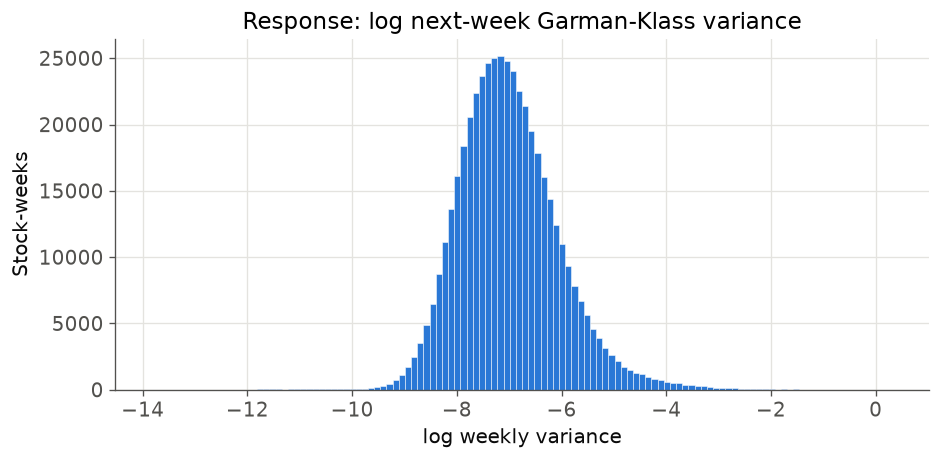

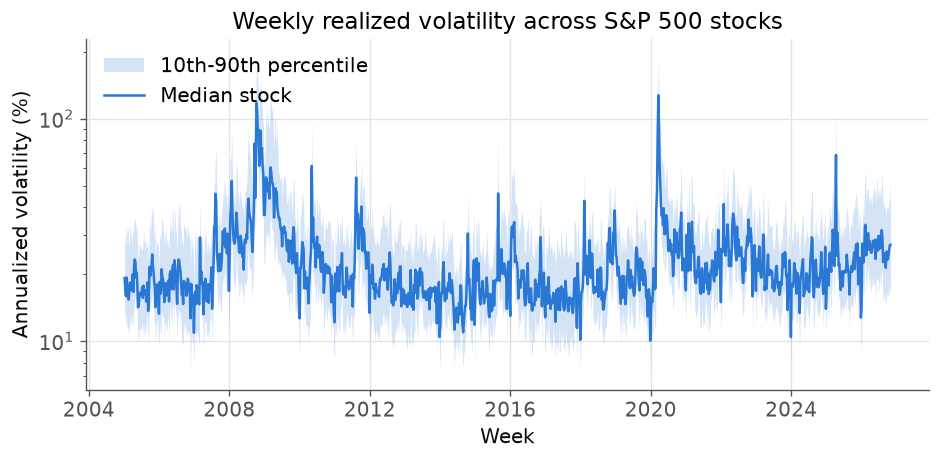

In [20]:
# Understand 3h: response distribution, volatility over time, and the share of stress weeks
from volforecast.plots import target_hist, volatility_over_time

target_hist(table["target"], IMAGES_PATH / "target_hist.png")
volatility_over_time(table["har_w"], table["week"], IMAGES_PATH / "volatility_over_time.png")
stress = table["VIXCLS"] >= 30
print(f"stress (VIX >= 30): {stress.mean():.1%} of stock-weeks, "
      f"{table.loc[stress, 'week'].nunique()} of {table['week'].nunique():,} weeks")
table.groupby(table["week"].dt.year)["target"].agg(["size", "mean", "std"]).round(2).T

### 3i. Is the daily-range target good enough?

The proposal flagged that free daily data rules out intraday realized variance, the measure the
volatility literature uses. Alpaca's 5-minute bars now allow a direct check for 2016 onward: the
weekly Garman-Klass variance against the weekly sum of squared 5-minute returns (both leave out
the overnight gap), for every company with cached 5-minute bars. Pooled over companies, a
correlation is helped by the gap between calm and volatile names, so we also report it within
each company, after removing that company's mean. A fresh run fetches only a 24-stock sample;
`scripts/build_rv5.py` fetches every member since 2016 (about two hours on the free plan), and the
numbers below come from that full run.

281,250 stock-weeks, 697 companies, correlation 0.952 pooled, 0.936 within company, mean log gap (GK - RV) -0.058


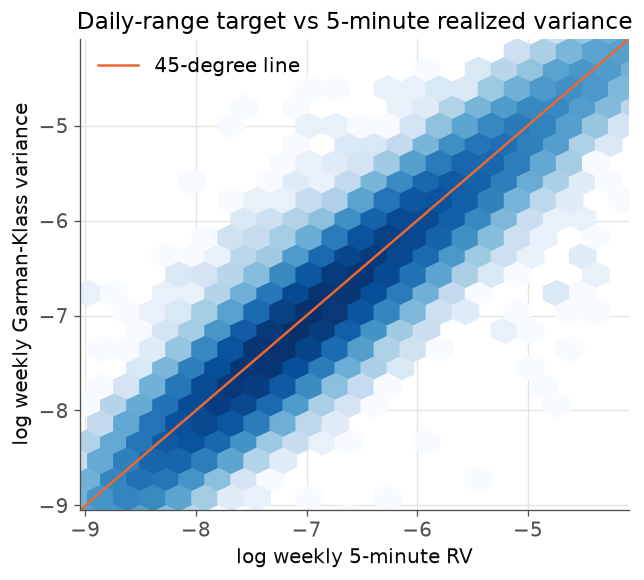

In [21]:
# Understand 3i: the Garman-Klass target against 5-minute realized variance
from volforecast.features import weekly_log_rv
from volforecast.plots import proxy_check

if rv5 is not None:
    both = table.set_index(["ticker", "week"])[["har_w"]].join(weekly_log_rv(rv5), how="inner")
    within = both - both.groupby(level="ticker").transform("mean")
    proxy_check(both["log_rv5"], both["har_w"], IMAGES_PATH / "proxy_check.png")
    print(f"{len(both):,} stock-weeks, {both.index.get_level_values('ticker').nunique()} companies, "
          f"correlation {both.corr().iloc[0, 1]:.3f} pooled, {within.corr().iloc[0, 1]:.3f} within company, "
          f"mean log gap (GK - RV) {(both['har_w'] - both['log_rv5']).mean():.3f}")

**Takeaway.** Over 281,250 stock-weeks for 697 companies since 2016, delisted ones included,
the log weekly Garman-Klass variance and the log weekly 5-minute realized variance have correlation
0.95 pooled and 0.94 within company, so the agreement is not just calm names against volatile ones.
The mean log gap is -0.06 (Garman-Klass about 6% lower), a level shift that any model absorbs. The
daily-range target is a sound proxy, which answers the main data concern of the proposal; weeks
before 2016 are not covered by this check.

### 3j. Scale of the features

In [22]:
# Understand 3j: ranges of the features; the widest and narrowest spreads
scale = table.drop(columns=["ticker", "week", "target"]).select_dtypes("number")
scale = scale.describe().T[["min", "max", "std"]].sort_values("std")
pd.concat([scale.head(4), scale.tail(4)])

,min,max,std
BETA60,-0.301575,0.019257,0.003573
BETA30,-0.409316,0.030937,0.004800
BETA20,-0.624716,0.061706,0.005708
VWAP0,0.871828,1.325657,0.006377
VIXCLS,9.140000,79.130000,8.169466
VSTD10,0.035853,7168.925293,10.433315
VMA5,0.200515,7527.233398,10.961516
VSTD5,0.007656,9891.583008,14.383092


**Takeaway.** Standard deviations run from 0.004 (`BETA60`) to 14 (`VSTD5`), and the volume
ratios reach 10,000 on near-empty trading days. Ridge and lasso therefore need every feature
standardized inside each training window, with the heavy-tailed volume ratios logged or clipped;
trees are unaffected by scale.

### 3k. Information leakage

Each feature must be known at the Friday close before the target week. How each block meets that:

| Risk | Control | Enforced by |
|---|---|---|
| Rolling windows reaching past the Friday | All windows end at the Friday close; the target is next week | `test_features_ignore_later_data`, `test_no_lookahead` |
| Earnings released after the close | An 8-K accepted after 16:00 ET counts for the next week; the filing time is a proxy for the announcement | `test_earnings_after_the_close_count_for_next_week` |
| Knowing the next earnings date | `earnings_next_week` extrapolates past announcement dates only | `add_earnings` |
| Earnings dates from 10-Q filings | Not used: a 10-Q is filed weeks after the announcement | design |
| Today's index list | Membership snapshot in force on each date; the last one, 2026-08-18, is carried forward to the end of the data | `restrict_to_spells` |
| Cleaning with later rows | Rules read one row, or the hand-built `RENAMES`, `WRONG_SERIES` and `BREAKS` tables, which fix identity, not outcomes | `clean` |
| Yahoo's back-adjusted prices | Every price feature is a ratio or a return, so split and dividend factors cancel | design |
| Overlapping targets across a split | A one-week gap between training and test windows | Milestone 3 split |
| Industry code (`sic2`) | SEC reports the current code, not the historical one; a mild look-ahead we accept | noted |

### 3l. What the free data misses: a CRSP check

Survivorship (3a) is the main weakness of the free data. CRSP, through Harvard's WRDS licence, has
every company ever in the index with daily prices, to 2025-12-31 in this vintage. Here the same
cleaning and weekly aggregation run on CRSP, keyed by CRSP's permanent security number, and the
result is compared with the free table year by year. The rest of this notebook uses free data only.
CRSP needs a personal WRDS account (`WRDS_USERNAME` in `.env`, the password in `~/.pgpass`,
`pip install -e ".[crsp]"`); without one this section is skipped.

CRSP: 3,746,413 stock-days, 94 removed by the bar rules, 549,738 stock-weeks


,"coverage, free","coverage, CRSP","stock-weeks, free","stock-weeks, CRSP","log variance, free - CRSP"
2005,0.553,1,14255,25989,-0.076
2006,0.578,1,14937,25985,-0.055
2007,0.602,1,15522,25985,-0.011
2008,0.631,1,16282,25984,-0.045
2009,0.657,1,17010,25992,-0.044
2010,0.679,1,17906,26492,-0.047
2011,0.692,1,17881,25993,-0.039
2012,0.717,1,18521,25993,-0.054
2013,0.739,1,19100,25995,-0.023
2014,0.755,1,19563,26058,-0.031


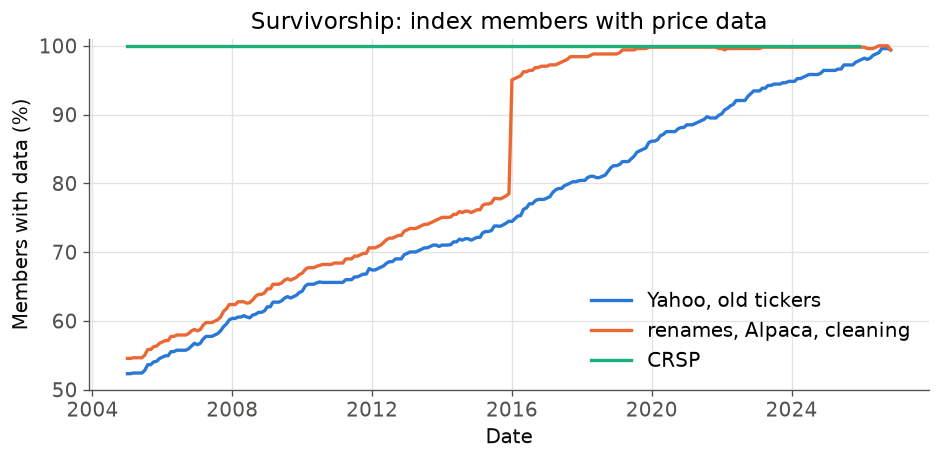

In [23]:
# Understand 3l: CRSP against the free data: coverage, sample size, level of the target
from volforecast.data import fetch_crsp, from_crsp
from volforecast.features import daily_measures, weekly_panel

CRSP_END = "2026-01-01"  # exclusive; CRSP updates once a year
HAS_CRSP = (DATA_PATH / "crsp" / "daily.parquet").exists() or bool(os.environ.get("WRDS_USERNAME"))
if HAS_CRSP:
    crsp_membership, crsp_daily = from_crsp(*fetch_crsp(START, CRSP_END, DATA_PATH / "crsp"))
    crsp_clean, crsp_steps = clean(crsp_daily, crsp_membership, set(), {}, CRSP_END)
    crsp_table = weekly_panel(daily_measures(crsp_clean)).query("in_index and target.notna()")
    shares_crsp = shares.assign(CRSP=coverage(crsp_membership, crsp_clean[crsp_clean["in_index"]]))
    plot_coverage(shares_crsp, IMAGES_PATH / "coverage_crsp.png")
    free_year, crsp_year = table["week"].dt.year, crsp_table["week"].dt.year
    compare = pd.DataFrame({
        "coverage, free": shares.iloc[:, 1].groupby(shares.index.year).mean(),
        "coverage, CRSP": shares_crsp["CRSP"].groupby(shares.index.year).mean(),
        "stock-weeks, free": free_year.value_counts(), "stock-weeks, CRSP": crsp_year.value_counts(),
        "log variance, free - CRSP": table.groupby(free_year)["har_w"].mean()
                                     - crsp_table.groupby(crsp_year)["har_w"].mean(),
    }).sort_index().loc[:2025]
    print(f"CRSP: {len(crsp_daily):,} stock-days, {crsp_steps['rows_removed'].iloc[2:].sum()} removed "
          f"by the bar rules, {len(crsp_table):,} stock-weeks")
    display(compare.round(3).convert_dtypes())
else:
    print("no WRDS access: CRSP check skipped")

**Takeaway.** CRSP covers every index member in every year, against 55% for the free data
in 2005. Before 2016 the free table has a third fewer stock-weeks (191,083 against 286,597), and
the companies it keeps are slightly calmer: averaged over 2005-2015, the free table's mean log
weekly variance is 0.04 below CRSP's in the same year, about 4% less variance. From 2016, with
Alpaca's delisted symbols, the yearly gap in mean log variance is at most 0.006; the free table
has 4% fewer stock-weeks in 2016 and under 1% fewer from 2019 to 2025. Survivorship therefore
costs training data before 2016 more than it biases the target, and its effect on the 2019-2026
test period is small, though CRSP cannot check 2026. Milestone 3 can train on CRSP to 2025 and use
the free sources only for 2026, if the TF agrees.

## **Phase 4**: Project question

### Revised question

For S&P 500 stocks, we forecast next week's log realized variance, measured by the Garman-Klass
estimator from daily prices (3i checks it against 5-minute realized variance). Models are trained
on 2005-2015, tuned on 2016-2018, and tested on 2019-2026 with yearly expanding refits, a one-week
gap at every boundary, and no tuning on test data.

1. **Accuracy.** Does a pooled model fit on all stocks (ridge and lasso, then gradient-boosted
   trees) on the HAR lags plus the feature blocks of 3e have lower mean QLIKE and MSE than a HAR
   regression fit per stock? The Diebold-Mariano test runs on the weekly cross-sectional mean of
   the loss differences, with Newey-West standard errors, at the 5% level. Per-stock HAR needs 52
   weeks of history; younger stocks use a HAR fit on all stocks, and every model is scored on the
   same rows.
2. **Attribution and regimes.** Which feature blocks carry any gain (refitting without each block),
   and does the gain keep its sign separately in calm weeks and in stress weeks (VIX at 30 or more
   on the Friday)?

It is answered when, for each model, the test-period table of QLIKE, MSE and Diebold-Mariano
statistics against HAR and the block-ablation table split by regime both exist.

### What changed from the proposal, and why

- **Economic value dropped**: no volatility-targeted portfolio, Sharpe ratio, drawdown or
  Fama-French regression, as the staff notes require.
- **Earnings timing** now comes from SEC 8-K Item 2.02 acceptance times, not 10-Q or XBRL dates,
  which arrive weeks after the announcement; whether next week holds an announcement is
  extrapolated from past dates only.
- **Fundamentals** (XBRL, only from mid-2009) are deferred: the question does not need them, and
  they would add a structural break in 2009.
- **Universe**: the point-in-time index with 30 renamed tickers recovered, 9 wrong Yahoo series
  removed and members Yahoo lacks filled from Alpaca from 2016; coverage before 2016 stays lower,
  so pre-2016 training data leans toward survivors.
- **Features** gained qlib's Alpha158 price-volume block, recomputed without qlib.
- **Stress** is defined by VIX at the Friday close, known at prediction time, rather than by
  calendar years.

### Decisions taken

- One row per stock-week; weeks end on Friday; the target needs at least 3 trading days.
- Prices are scaled by `adj_close / close`; a variance floor of 1e-6 keeps logs finite.
- No row is dropped for a missing feature: trees take NaN, and the linear models will impute the
  training-window median with a missing-value indicator.
- Linear models standardize every feature inside each training window.

### Open questions for the TF

1. May we use CRSP through Harvard's WRDS license to remove the pre-2016 survivorship bias, even
   though the proposal promised free public data?
2. Do HAR, GARCH(1,1), QLIKE and the Diebold-Mariano test meet the AC209A outside-method
   requirement?
3. Is the 2019-2026 test with yearly expanding refits acceptable, or would you prefer one fit?

### Next steps (Milestone 3)

EDA of the target and feature blocks; per-stock HAR and GARCH(1,1), ridge/lasso and gradient-boosted
trees on the split above; an evaluation module with QLIKE, MSE and the Diebold-Mariano test.

In [24]:
# Export the numbers the slides and the revised proposal quote, so the three cannot drift apart
year_cov = shares.groupby(shares.index.year).mean()
numbers = {
    "nSnapshots": f"{per_date.size:,}", "nUniverse": f"{len(TICKERS):,}",
    "nOldTickers": f"{len(universe(raw_membership, START)):,}",
    "nYahoo": f"{N_YAHOO:,}",
    "nAlpaca": f"{daily.loc[daily['source'] == 'alpaca', 'ticker'].nunique():,}",
    "nNoData": f"{len(missing):,}", "nRenames": f"{len(RENAMES)}", "nWrong": f"{len(WRONG_SERIES)}", "nBreaks": f"{len(BREAKS)}",
    "nRawRows": f"{len(daily):,}", "nCleanRows": f"{len(clean_daily):,}",
    "dataMB": f"{sizes.sum():.0f}", "nTableRows": f"{len(table):,}", "nTableCols": f"{table.shape[1]}",
    "nCompanies": f"{table['ticker'].nunique():,}", "nWeeks": f"{table['week'].nunique():,}",
    "covEarly": f"{year_cov.iloc[0, 1]:.0%}", "covEarlyRaw": f"{year_cov.iloc[0, 0]:.0%}",
    "covTest": f"{year_cov.loc[2019, shares.columns[1]]:.1%}", "covEnd": f"{year_cov.iloc[-1, 1]:.1%}",
    "stressShare": f"{stress.mean():.1%}", "nStressWeeks": f"{table.loc[stress, 'week'].nunique()}",
    "nZeroRange": f"{zero_range.sum():,}",
}
numbers |= {"rvCorr": "n/a", "rvCorrWithin": "n/a", "rvN": "0", "rvCompanies": "0", "rvGap": "n/a"}  # no Alpaca
if rv5 is not None:
    numbers |= {"rvCorr": f"{both.corr().iloc[0, 1]:.2f}", "rvCorrWithin": f"{within.corr().iloc[0, 1]:.2f}",
                "rvN": f"{len(both):,}", "rvCompanies": f"{both.index.get_level_values('ticker').nunique()}",
                "rvGap": f"{(both['har_w'] - both['log_rv5']).mean():.2f}"}
numbers |= {"crspWeeksFree": "n/a", "crspWeeksCrsp": "n/a", "crspGap": "n/a"}  # no WRDS
if HAS_CRSP:
    pre = compare.loc[2005:2015]
    numbers |= {"crspWeeksFree": f"{pre['stock-weeks, free'].sum():,.0f}",
                "crspWeeksCrsp": f"{pre['stock-weeks, CRSP'].sum():,.0f}",
                "crspGap": f"{-pre['log variance, free - CRSP'].mean():.2f}"}  # how much lower
esc = {k: v.replace("%", r"\%") for k, v in numbers.items()}
tex = "\n".join(rf"\newcommand{{\{k}}}{{{v}}}" for k, v in esc.items())
Path("deliverables/ms2").mkdir(parents=True, exist_ok=True)
Path("deliverables/ms2/numbers.tex").write_text("% Written by ms2.ipynb; do not edit.\n" + tex + "\n")
print(tex)

\newcommand{\nSnapshots}{2,720}
\newcommand{\nUniverse}{950}
\newcommand{\nOldTickers}{977}
\newcommand{\nYahoo}{677}
\newcommand{\nAlpaca}{165}
\newcommand{\nNoData}{108}
\newcommand{\nRenames}{30}
\newcommand{\nWrong}{9}
\newcommand{\nBreaks}{4}
\newcommand{\nRawRows}{3,423,011}
\newcommand{\nCleanRows}{2,315,615}
\newcommand{\dataMB}{473}
\newcommand{\nTableRows}{473,684}
\newcommand{\nTableCols}{183}
\newcommand{\nCompanies}{725}
\newcommand{\nWeeks}{1,139}
\newcommand{\covEarly}{55\%}
\newcommand{\covEarlyRaw}{53\%}
\newcommand{\covTest}{99.4\%}
\newcommand{\covEnd}{99.8\%}
\newcommand{\stressShare}{7.3\%}
\newcommand{\nStressWeeks}{89}
\newcommand{\nZeroRange}{80}
\newcommand{\rvCorr}{0.95}
\newcommand{\rvCorrWithin}{0.94}
\newcommand{\rvN}{281,250}
\newcommand{\rvCompanies}{697}
\newcommand{\rvGap}{-0.06}
\newcommand{\crspWeeksFree}{191,083}
\newcommand{\crspWeeksCrsp}{286,597}
\newcommand{\crspGap}{0.04}
